# Actividad — Flujo de evaluación completo: detección de fraude
**Aprendizaje Supervisado · Sesión 12 · Evaluación de modelos y ajuste de hiperparámetros**
**Estudiante:** Julian Emiliano Ortiz Rivero

**Qué haremos.** En la presentación vimos que la exactitud puede engañar con clases desbalanceadas, y qué hacer al respecto: métricas más honestas (MCC, kappa de Cohen, log-loss), estrategias contra el desbalance (`class_weight`, sobremuestreo, SMOTE), búsqueda de hiperparámetros (`GridSearchCV` vs. `RandomizedSearchCV`) y calibración de probabilidades. Aquí armamos ese flujo completo sobre un conjunto sintético de detección de fraude.

Trabaja de forma **individual**. Donde veas `...` con un comentario `# ✏️`, completa esa línea; donde veas **✏️ Pregunta**, responde en la celda de markdown siguiente.

## Parte 0 — Los datos  *(presentación A1–A4)*

Generamos un conjunto sintético de detección de fraude: 5000 transacciones, 12 variables numéricas, y solo ~2 % de la clase positiva (fraude) — el mismo tipo de desbalance que vimos en los ejemplos de la presentación (980 legítimas / 20 fraudulentas, aquí a mayor escala).

In [1]:
import warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, matthews_corrcoef, cohen_kappa_score,
                              log_loss, brier_score_loss, make_scorer)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.frozen import FrozenEstimator
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from scipy.stats import randint
warnings.filterwarnings("ignore")

X, y = make_classification(n_samples=5000, n_features=12, n_informative=6, n_redundant=2,
                            n_clusters_per_class=2, weights=[0.98, 0.02], flip_y=0.01,
                            class_sep=1.0, random_state=0)
cols = [f"x{i}" for i in range(12)]
X = pd.DataFrame(X, columns=cols)

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
mcc_scorer = make_scorer(matthews_corrcoef)

print("Entrenamiento:", Xtr.shape, " Prueba:", Xte.shape,
      " Proporción de fraude (entrenamiento):", round(ytr.mean(), 4))

Entrenamiento: (3750, 12)  Prueba: (1250, 12)  Proporción de fraude (entrenamiento): 0.0229


## Parte 1 — Modelo base: exactitud, MCC y kappa  *(presentación B1–B5)*

Entrenamos un `RandomForestClassifier` sin ningún tratamiento especial para el desbalance, y comparamos qué tan distinto se ve su desempeño según la métrica que usemos.

In [2]:
modelo_base = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=1).fit(Xtr, ytr)
pred_base = modelo_base.predict(Xte)

exactitud_base = accuracy_score(yte, pred_base)
mcc_base = matthews_corrcoef(yte, pred_base)
kappa_base = cohen_kappa_score(yte, pred_base)

print(f"Exactitud = {exactitud_base:.3f}")
print(f"MCC       = {mcc_base:.3f}")
print(f"Kappa     = {kappa_base:.3f}")

Exactitud = 0.982
MCC       = 0.459
Kappa     = 0.348


✏️ **Pregunta 1.1.** (a) ¿Qué tan distinta es la historia que cuenta la exactitud frente a la que cuentan MCC y kappa? (b) Dado lo que vimos en B2–B3 de la presentación, ¿por qué MCC y kappa caen tan parecido aquí? (c) Si el modelo fuera el de "todo negativo" (nunca predice fraude), ¿qué exactitud tendría aproximadamente, dado el desbalance del dataset?

**Respuesta:** La exactitud de 0.982 parece excelente, pero el MCC de 0.459 y el kappa de 0.348 muestran que el desempeño sobre la clase minoritaria es mucho más limitado. MCC y kappa quedan relativamente cerca porque ambos consideran el acuerdo más allá de los aciertos esperados por azar. Un modelo que siempre predijera no fraude tendría cerca de 97.7 % de exactitud, ya que solo 2.3 % de las transacciones de entrenamiento pertenece a la clase fraude.

## Parte 2 — Log-loss contra un modelo "todo negativo"  *(presentación B6–B9)*

Calculamos el log-loss del modelo base usando `predict_proba`, y lo comparamos contra el de un modelo que siempre predice "no fraude" (`DummyClassifier`).

In [3]:
proba_base = modelo_base.predict_proba(Xte)[:, 1]
logloss_base = log_loss(yte, proba_base)

modelo_negativo = DummyClassifier(strategy="most_frequent").fit(Xtr, ytr)
proba_negativo = modelo_negativo.predict_proba(Xte)[:, 1]
logloss_negativo = log_loss(yte, proba_negativo)

print(f"log-loss modelo base     = {logloss_base:.3f}")
print(f"log-loss todo-negativo   = {logloss_negativo:.3f}")

log-loss modelo base     = 0.081
log-loss todo-negativo   = 0.807


✏️ **Pregunta 2.1.** (a) ¿Por qué el log-loss del modelo "todo negativo" es tan alto, si su exactitud es casi tan buena como la del modelo base? (b) Conecta esto con B6 de la presentación: ¿qué tipo de error castiga el log-loss que la exactitud no ve?

**Respuesta:** El modelo todo negativo conserva una exactitud alta porque acierta la clase de la mayoría. Su log-loss sube a 0.807 porque asigna probabilidad cero a los fraudes reales y recibe una penalización fuerte por estar completamente seguro de una predicción incorrecta. La exactitud solo observa la clase final, mientras que log-loss también toma en cuenta la confianza.

## Parte 3 — Tres estrategias contra el desbalance  *(presentación C1–C9)*

Comparamos `class_weight="balanced"`, `RandomOverSampler` y `SMOTE`, todas evaluadas con validación cruzada y **MCC** como métrica. Usamos un `Pipeline` de `imbalanced-learn` para que el remuestreo se aplique *solo* dentro de cada fold de entrenamiento — si remuestreamos antes de la validación cruzada, se filtran copias del mismo caso entre entrenamiento y validación y el MCC sale artificialmente perfecto.

In [4]:
def mcc_cv(estimator):
    return cross_val_score(estimator, Xtr, ytr, cv=kf, scoring=mcc_scorer).mean()

mcc_balanced = mcc_cv(RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                              random_state=0, n_jobs=1))

pipe_ros = ImbPipeline([
    ("ros", RandomOverSampler(random_state=0)),
    ("clf", RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=1)),
])
mcc_ros = mcc_cv(pipe_ros)

pipe_smote = ImbPipeline([
    ("smote", SMOTE(random_state=0)),
    ("clf", RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=1)),
])
mcc_smote = mcc_cv(pipe_smote)

tabla_desbalance = pd.DataFrame({
    "estrategia": ["class_weight=balanced", "RandomOverSampler", "SMOTE"],
    "mcc_cv": [mcc_balanced, mcc_ros, mcc_smote],
}).sort_values("mcc_cv", ascending=False).reset_index(drop=True)
tabla_desbalance

,estrategia,mcc_cv
0,class_weight=balanced,0.469947
1,SMOTE,0.454849
2,RandomOverSampler,0.429607


✏️ **Pregunta 3.1.** (a) ¿Por qué hay que meter el remuestreo dentro del `Pipeline` en vez de aplicarlo una sola vez antes de `cross_val_score`? (b) ¿Qué estrategia ganó en tu corrida? (c) ¿Las tres quedaron muy parecidas o muy distintas? ¿Qué nos dice eso sobre qué tan severo es realmente el desbalance para este dataset (relaciona con C7–C8)?

**Respuesta:** El remuestreo debe quedar dentro del Pipeline para que se aplique únicamente a la parte de entrenamiento de cada pliegue. Si se realiza antes, una copia o un punto sintético relacionado puede aparecer en entrenamiento y validación, lo que infla el MCC. Ganó class_weight=balanced con 0.470, seguido de SMOTE con 0.455 y RandomOverSampler con 0.430. Las diferencias son moderadas. El desbalance es fuerte por frecuencia, pero crear más muestras no aportó una mejora clara frente a ponderar la clase minoritaria.

## Parte 4 — GridSearchCV vs. RandomizedSearchCV  *(presentación D1–D8)*

Tomamos la estrategia ganadora de la Parte 3 y ajustamos sus hiperparámetros con **el mismo presupuesto** de evaluaciones (8 combinaciones) usando `GridSearchCV` y `RandomizedSearchCV`, y comparamos tiempo y resultado.

In [5]:
def estimador_para(estrategia):
    rf = RandomForestClassifier(random_state=0, n_jobs=1)
    if estrategia == "class_weight=balanced":
        return RandomForestClassifier(class_weight="balanced", random_state=0, n_jobs=1)
    sampler = RandomOverSampler(random_state=0) if estrategia == "RandomOverSampler" else SMOTE(random_state=0)
    return ImbPipeline([("sampler", sampler), ("clf", rf)])

ganadora = tabla_desbalance.loc[0, "estrategia"]
base_estimador = estimador_para(ganadora)
prefijo = "" if ganadora == "class_weight=balanced" else "clf__"

malla = {f"{prefijo}n_estimators": [100, 200], f"{prefijo}max_depth": [None, 10], f"{prefijo}min_samples_leaf": [1, 3]}
dist = {f"{prefijo}n_estimators": randint(100, 251), f"{prefijo}max_depth": [None, 10], f"{prefijo}min_samples_leaf": randint(1, 4)}

t0 = time.time()
grid = GridSearchCV(base_estimador, malla, cv=kf, scoring=mcc_scorer, n_jobs=1).fit(Xtr, ytr)
t_grid = time.time() - t0

t0 = time.time()
rand = RandomizedSearchCV(base_estimador, dist, n_iter=8, cv=kf, scoring=mcc_scorer,
                           random_state=0, n_jobs=1).fit(Xtr, ytr)
t_rand = time.time() - t0

print(f"Estrategia ganadora de la Parte 3: {ganadora}")
print(f"GridSearchCV       : mejor MCC = {grid.best_score_:.3f}  params={grid.best_params_}  tiempo={t_grid:.1f}s")
print(f"RandomizedSearchCV : mejor MCC = {rand.best_score_:.3f}  params={rand.best_params_}  tiempo={t_rand:.1f}s")

mejor_busqueda = grid if grid.best_score_ >= rand.best_score_ else rand
modelo_final = mejor_busqueda.best_estimator_

Estrategia ganadora de la Parte 3: class_weight=balanced
GridSearchCV       : mejor MCC = 0.509  params={'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 100}  tiempo=24.8s
RandomizedSearchCV : mejor MCC = 0.507  params={'max_depth': 10, 'min_samples_leaf': 2, 'n_estimators': 125}  tiempo=23.0s


✏️ **Pregunta 4.1.** (a) ¿Cuál de las dos búsquedas dio mejor MCC con el mismo presupuesto? (b) Con solo 3 hiperparámetros y una malla pequeña como esta, ¿esperarías una diferencia grande entre grid y random (relaciona con D5)? (c) ¿En qué escenario sí la verías?

**Respuesta:** GridSearchCV obtuvo el mejor MCC con 0.509, frente a 0.507 de RandomizedSearchCV. La diferencia de 0.002 es mínima porque solo se ajustaron tres hiperparámetros sobre una malla pequeña de ocho combinaciones. RandomizedSearchCV tendría una ventaja más clara con muchos hiperparámetros, rangos continuos amplios o un presupuesto que no permita recorrer toda la malla.

## Parte 5 — Calibración: antes y después  *(presentación E1–E8)*

Separamos una porción de entrenamiento como conjunto de calibración, "congelamos" el modelo ya ajustado con `FrozenEstimator` y comparamos la curva de confiabilidad y el log-loss/Brier score antes y después de calibrar.

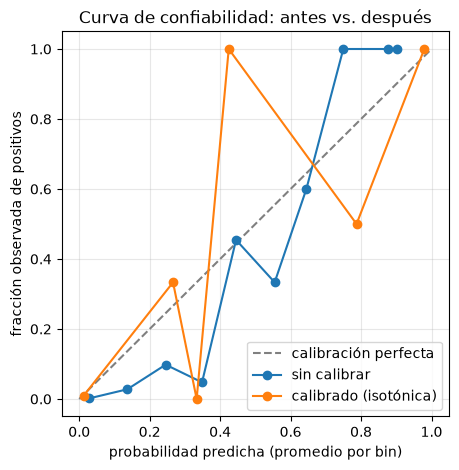

log-loss sin calibrar = 0.116   log-loss calibrado = 0.107
Brier sin calibrar    = 0.019   Brier calibrado    = 0.014


In [6]:
Xtr2, Xcal, ytr2, ycal = train_test_split(Xtr, ytr, test_size=0.3, stratify=ytr, random_state=0)

# reentrenamos SOLO sobre Xtr2 (sin ver Xcal) para poder calibrar despues con Xcal
base_sin_calibrar = estimador_para(ganadora).set_params(**mejor_busqueda.best_params_).fit(Xtr2, ytr2)
proba_sin_cal = base_sin_calibrar.predict_proba(Xte)[:, 1]

cal = CalibratedClassifierCV(FrozenEstimator(base_sin_calibrar), method="isotonic").fit(Xcal, ycal)
proba_con_cal = cal.predict_proba(Xte)[:, 1]

frac_sin, prob_sin = calibration_curve(yte, proba_sin_cal, n_bins=10)
frac_con, prob_con = calibration_curve(yte, proba_con_cal, n_bins=10)

plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], "--", color="gray", label="calibración perfecta")
plt.plot(prob_sin, frac_sin, "o-", label="sin calibrar")
plt.plot(prob_con, frac_con, "o-", label="calibrado (isotónica)")
plt.xlabel("probabilidad predicha (promedio por bin)")
plt.ylabel("fracción observada de positivos")
plt.legend(); plt.title("Curva de confiabilidad: antes vs. después"); plt.grid(alpha=0.3)
plt.show()

print(f"log-loss sin calibrar = {log_loss(yte, proba_sin_cal):.3f}   log-loss calibrado = {log_loss(yte, proba_con_cal):.3f}")
print(f"Brier sin calibrar    = {brier_score_loss(yte, proba_sin_cal):.3f}   Brier calibrado    = {brier_score_loss(yte, proba_con_cal):.3f}")

✏️ **Pregunta 5.1.** (a) ¿El log-loss y el Brier score mejoraron o empeoraron después de calibrar? (b) Si empeoraron, usa E8 de la presentación para proponer una explicación (piensa en cuántos casos de fraude quedaron en `Xcal`). (c) ¿Qué harías distinto para darle una mejor oportunidad a la calibración?

**Respuesta:** La calibración mejoró el log-loss de 0.116 a 0.107 y el Brier score de 0.019 a 0.014 cuando se comparó sobre el mismo modelo entrenado con Xtr2. El conjunto Xcal contiene cerca de 26 fraudes, por lo que la estimación isotónica puede ser inestable aunque esta vez haya mejorado. Para darle una mejor oportunidad usaría más datos de calibración, probaría el método sigmoid o emplearía calibración con validación cruzada.

## Parte 6 — Comparación final y recomendación

Reunimos el modelo base, el mejor modelo de la búsqueda de hiperparámetros (Parte 4) y su versión calibrada (Parte 5) en una sola tabla.

In [7]:
filas = []
for nombre, m, proba in [
    ("Modelo base (sin tratar desbalance)", modelo_base, proba_base),
    (f"Mejor modelo ({ganadora} + {type(mejor_busqueda).__name__})", modelo_final, modelo_final.predict_proba(Xte)[:, 1]),
    ("Mejor modelo + calibrado", cal, proba_con_cal),
]:
    pred = (proba >= 0.5).astype(int)
    filas.append({
        "modelo": nombre,
        "exactitud": round(accuracy_score(yte, pred), 3),
        "mcc": round(matthews_corrcoef(yte, pred), 3),
        "kappa": round(cohen_kappa_score(yte, pred), 3),
        "log_loss": round(log_loss(yte, proba), 3),
    })

tabla_final = pd.DataFrame(filas)
tabla_final.to_csv("resultados-evaluacion-fraude.csv", index=False)
tabla_final

,modelo,exactitud,mcc,kappa,log_loss
0,Modelo base (sin tratar desbalance),0.982,0.459,0.348,0.081
1,Mejor modelo (class_weight=balanced + GridSear...,0.986,0.608,0.584,0.086
2,Mejor modelo + calibrado,0.982,0.498,0.468,0.107


✏️ **Pregunta 6.1.** (6 a 8 líneas) Con la tabla anterior: (1) ¿qué modelo recomendarías para producción: el mejor ajustado sin calibrar, o la versión calibrada? ¿Por qué? (2) ¿El modelo final (Parte 4) mejoró claramente sobre el modelo base de la Parte 1 en MCC/kappa? (3) Si tuvieras que fijar un umbral de decisión distinto de 0.5 para decidir "alerta de fraude", ¿lo subirías o lo bajarías respecto al modelo base? ¿Por qué (piensa en el costo de un falso positivo vs. un falso negativo en fraude)? (4) ¿Qué parte del flujo completo (desbalance, búsqueda de hiperparámetros, o calibración) tuvo el mayor impacto en tus resultados?

**Respuesta:** Recomendaría el modelo ajustado sin calibrar para la decisión final con umbral 0.5.

Obtuvo MCC de 0.608 y kappa de 0.584, los mejores valores de la tabla.

La versión calibrada quedó en MCC de 0.498 y kappa de 0.468 porque usó menos datos para entrenar.

El modelo ajustado sí mejoró claramente al modelo base, cuyo MCC fue 0.459.

Para una alerta de fraude bajaría el umbral si el costo de omitir un fraude supera al de revisar una alerta falsa.

El umbral exacto lo elegiría con validación y con el costo real de cada tipo de error.

El mayor impacto provino del tratamiento del desbalance junto con la búsqueda de hiperparámetros.